# TA-05: Klasifikasi Kelangsungan Hidup Penumpang Titanic dengan Decision Tree
**Mata Praktikum:** Pembelajaran Mesin · **Modul 05:** Algoritma Decision Tree

Notebook ini berisi alur lengkap: EDA → preprocessing → Model A (tanpa batas / overfit) → Model B (pruning) → evaluasi → visualisasi pohon → feature importance → simpan model (Joblib).

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

sns.set_theme(style='whitegrid')
os.makedirs('../reports', exist_ok=True); os.makedirs('../model', exist_ok=True)

## 1. Memuat Dataset

In [2]:
df_raw = sns.load_dataset('titanic')
df_raw.to_csv('../data/titanic.csv', index=False)   # salinan lokal agar reproducible
print(df_raw.shape)
df_raw.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Eksplorasi Data (EDA)

In [3]:
fitur = ['pclass','sex','age','sibsp','parch','fare','embarked']
df = df_raw[['survived'] + fitur].copy()
print(df.dtypes, '\n')
print('Missing values:'); print(df.isna().sum())
df.describe()

survived      int64
pclass        int64
sex          object
age         float64
sibsp         int64
parch         int64
fare        float64
embarked     object
dtype: object 

Missing values:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


/tmp/ipykernel_129/1895390830.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_title('Distribusi Variabel Target'); ax.set_xticklabels(['Tidak Selamat (0)','Selamat (1)'])


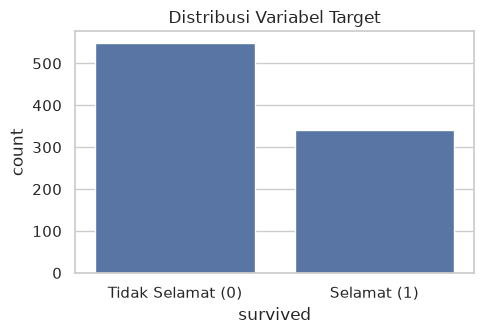

survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [4]:
fig, ax = plt.subplots(figsize=(5,3.5))
sns.countplot(x='survived', data=df, ax=ax)
ax.set_title('Distribusi Variabel Target'); ax.set_xticklabels(['Tidak Selamat (0)','Selamat (1)'])
plt.tight_layout(); plt.savefig('../reports/01_target.png', dpi=150); plt.show()
print(df['survived'].value_counts(normalize=True).round(3))

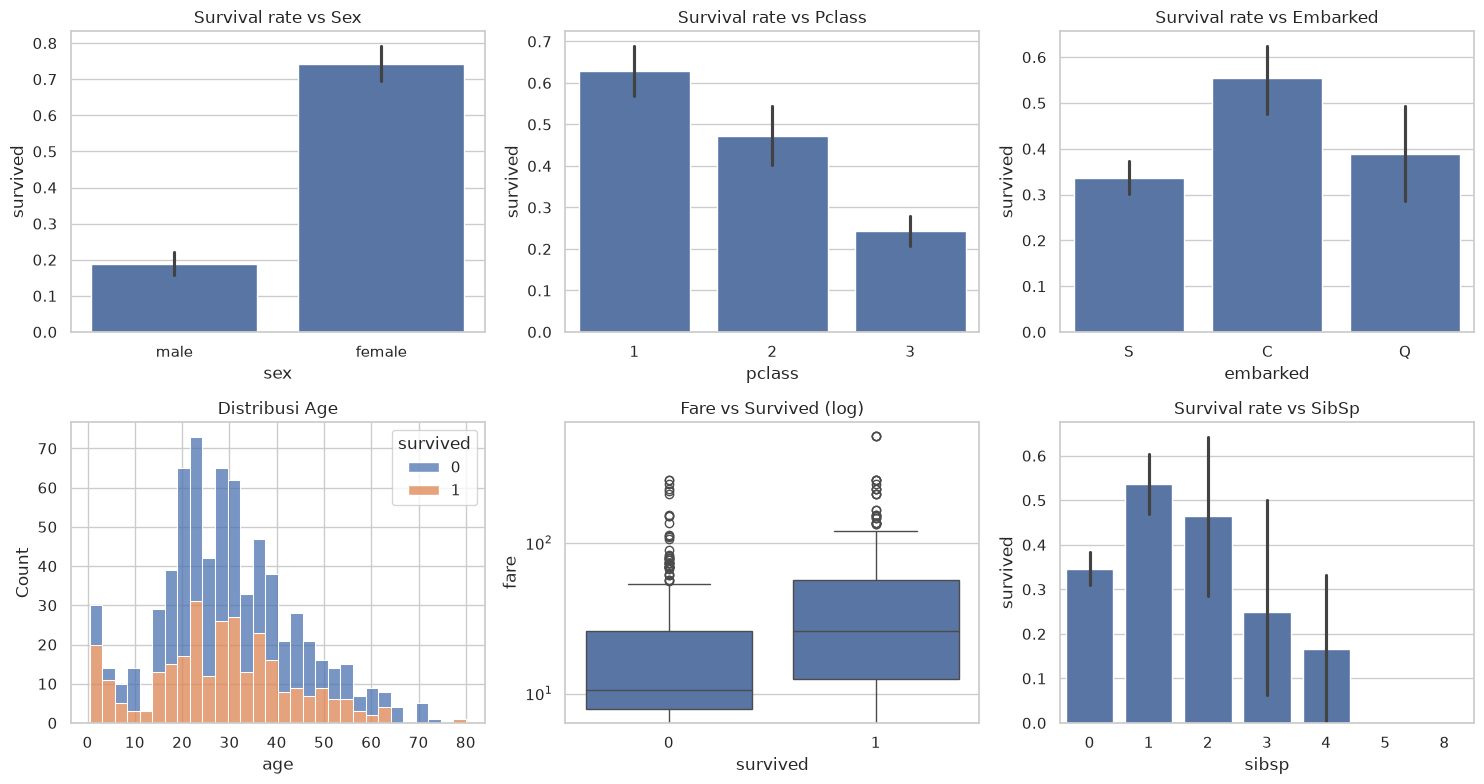

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.barplot(x='sex', y='survived', data=df, ax=axes[0,0]);      axes[0,0].set_title('Survival rate vs Sex')
sns.barplot(x='pclass', y='survived', data=df, ax=axes[0,1]);   axes[0,1].set_title('Survival rate vs Pclass')
sns.barplot(x='embarked', y='survived', data=df, ax=axes[0,2]); axes[0,2].set_title('Survival rate vs Embarked')
sns.histplot(data=df, x='age', hue='survived', bins=30, multiple='stack', ax=axes[1,0]); axes[1,0].set_title('Distribusi Age')
sns.boxplot(x='survived', y='fare', data=df, ax=axes[1,1]); axes[1,1].set_yscale('log'); axes[1,1].set_title('Fare vs Survived (log)')
sns.barplot(x='sibsp', y='survived', data=df, ax=axes[1,2]);    axes[1,2].set_title('Survival rate vs SibSp')
plt.tight_layout(); plt.savefig('../reports/02_eda.png', dpi=150); plt.show()

**Temuan EDA:** perempuan jauh lebih banyak selamat daripada laki-laki, penumpang kelas 1 punya survival rate tertinggi, dan anak kecil cenderung lebih banyak selamat. Kelas target tidak seimbang ringan (± 62% tidak selamat vs 38% selamat).

## 3. Pra-pemrosesan Data
- **Missing value:** `age` (177 baris) → median; `embarked` (2 baris) → modus.
- **Fitur kategorikal:** `sex` dan `embarked` → One-Hot Encoding (`pd.get_dummies`).

In [6]:
median_age = float(df['age'].median())
mode_embarked = df['embarked'].mode()[0]
df['age'] = df['age'].fillna(median_age)
df['embarked'] = df['embarked'].fillna(mode_embarked)
print('Sisa missing value:', int(df.isna().sum().sum()))

df_enc = pd.get_dummies(df, columns=['sex','embarked'], dtype=int)
X = df_enc.drop('survived', axis=1)
y = df_enc['survived']
print(list(X.columns))
X.head()

Sisa missing value: 0
['pclass', 'age', 'sibsp', 'parch', 'fare', 'sex_female', 'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S']


,pclass,age,sibsp,parch,fare,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0
2,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1
4,3,35.0,0,0,8.0500,0,1,0,0,1


## 4. Split Data & Pelatihan Model

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

# Model A: tanpa batasan (potensi overfit)
model_a = DecisionTreeClassifier(max_depth=None, random_state=42).fit(X_train, y_train)
# Model B: pruning (pre-pruning dengan max_depth=3)
model_b = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print('Kedalaman Model A:', model_a.get_depth(), '| Jumlah daun:', model_a.get_n_leaves())
print('Kedalaman Model B:', model_b.get_depth(), '| Jumlah daun:', model_b.get_n_leaves())

(623, 10) (268, 10)
Kedalaman Model A: 18 | Jumlah daun: 148
Kedalaman Model B: 3 | Jumlah daun: 8


## 5. Evaluasi & Perbandingan Model A vs B

In [8]:
hasil = {}
for nama, m in [('Model A (max_depth=None)', model_a), ('Model B (max_depth=3)', model_b)]:
    pred = m.predict(X_test)
    hasil[nama] = dict(train=accuracy_score(y_train, m.predict(X_train)), test=accuracy_score(y_test, pred))
    print('='*60); print(nama)
    print('Confusion Matrix:'); print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=['Tidak Selamat','Selamat']))

cmp = pd.DataFrame(hasil).T
cmp['gap (train-test)'] = cmp['train'] - cmp['test']
cmp.round(4)

Model A (max_depth=None)
Confusion Matrix:
[[138  27]
 [ 37  66]]
               precision    recall  f1-score   support

Tidak Selamat       0.79      0.84      0.81       165
      Selamat       0.71      0.64      0.67       103

     accuracy                           0.76       268
    macro avg       0.75      0.74      0.74       268
 weighted avg       0.76      0.76      0.76       268

Model B (max_depth=3)
Confusion Matrix:
[[157   8]
 [ 47  56]]
               precision    recall  f1-score   support

Tidak Selamat       0.77      0.95      0.85       165
      Selamat       0.88      0.54      0.67       103

     accuracy                           0.79       268
    macro avg       0.82      0.75      0.76       268
 weighted avg       0.81      0.79      0.78       268



,train,test,gap (train-test)
Model A (max_depth=None),0.9791,0.7612,0.2179
Model B (max_depth=3),0.8299,0.7948,0.0351


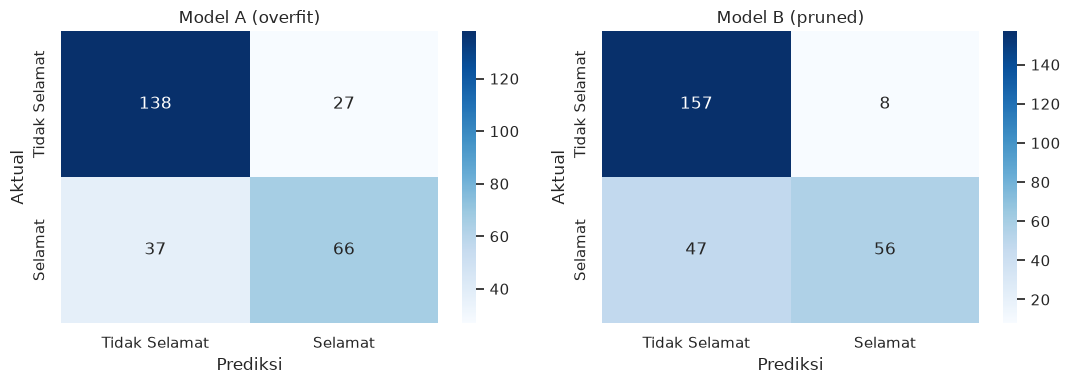

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nama, m) in zip(axes, [('Model A (overfit)', model_a), ('Model B (pruned)', model_b)]):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Tidak Selamat','Selamat'], yticklabels=['Tidak Selamat','Selamat'])
    ax.set_title(nama); ax.set_xlabel('Prediksi'); ax.set_ylabel('Aktual')
plt.tight_layout(); plt.savefig('../reports/03_confusion.png', dpi=150); plt.show()

### Analisis Overfitting: kurva akurasi vs `max_depth`

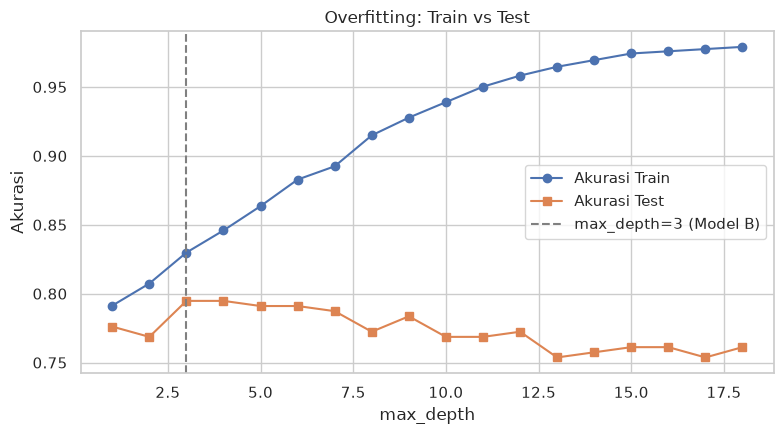

In [10]:
depths = list(range(1, 19))
tr, te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    tr.append(m.score(X_train, y_train)); te.append(m.score(X_test, y_test))
plt.figure(figsize=(8,4.5))
plt.plot(depths, tr, 'o-', label='Akurasi Train'); plt.plot(depths, te, 's-', label='Akurasi Test')
plt.axvline(3, color='gray', ls='--', label='max_depth=3 (Model B)')
plt.xlabel('max_depth'); plt.ylabel('Akurasi'); plt.title('Overfitting: Train vs Test'); plt.legend()
plt.tight_layout(); plt.savefig('../reports/04_overfitting_curve.png', dpi=150); plt.show()

**Catatan trade-off:** Model B sangat baik mengenali yang *tidak selamat* (recall 0,95) tetapi recall kelas *Selamat* hanya 0,54, sehingga model cenderung konservatif. Model A lebih seimbang di kelas Selamat (recall 0,64) namun akurasi keseluruhan lebih rendah dan tidak stabil.

**Analisis:** Model A tumbuh hingga kedalaman ±18 dan menghafal data latih (akurasi train ≈ 98%), tetapi akurasi test hanya ≈ 76%. Model B (depth=3) memiliki akurasi train ≈ 83% dan test ≈ 79,5%, sehingga selisih (gap) train–test (±3,5 poin vs ±21,8 poin pada Model A) jauh lebih kecil, artinya generalisasi lebih baik dan modelnya jauh lebih sederhana. Kurva menunjukkan akurasi test stagnan di kisaran 79% sejak depth 3–4 sementara akurasi train terus naik: tanda klasik overfitting.

## 6. Visualisasi Pohon (Model B)

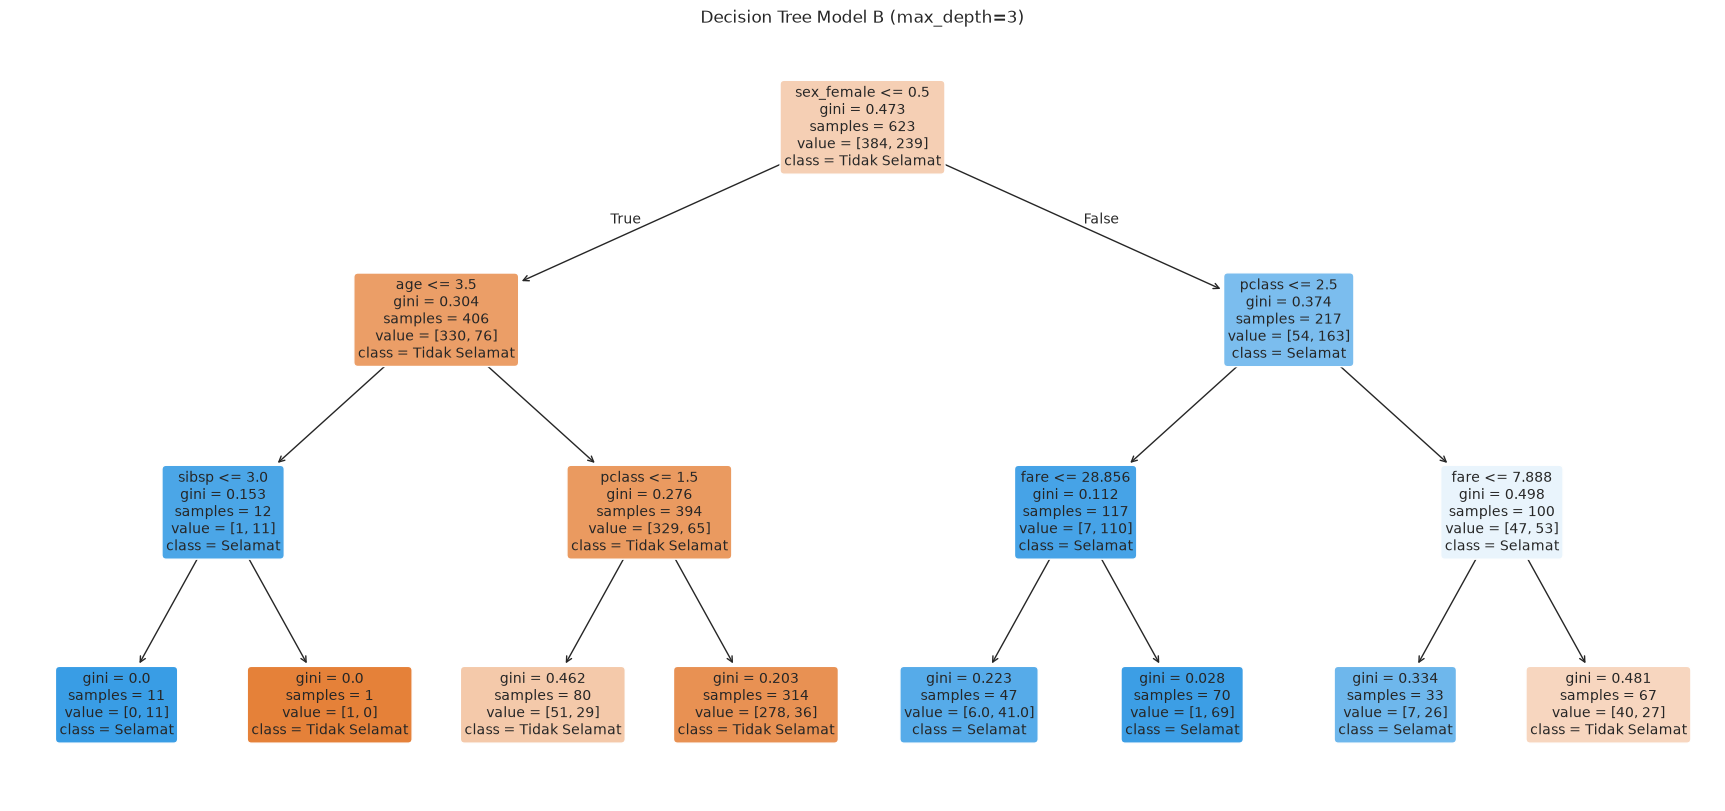

|--- sex_female <= 0.50
|   |--- age <= 3.50
|   |   |--- sibsp <= 3.00
|   |   |   |--- class: 1
|   |   |--- sibsp >  3.00
|   |   |   |--- class: 0
|   |--- age >  3.50
|   |   |--- pclass <= 1.50
|   |   |   |--- class: 0
|   |   |--- pclass >  1.50
|   |   |   |--- class: 0
|--- sex_female >  0.50
|   |--- pclass <= 2.50
|   |   |--- fare <= 28.86
|   |   |   |--- class: 1
|   |   |--- fare >  28.86
|   |   |   |--- class: 1
|   |--- pclass >  2.50
|   |   |--- fare <= 7.89
|   |   |   |--- class: 1
|   |   |--- fare >  7.89
|   |   |   |--- class: 0



In [11]:
plt.figure(figsize=(22, 10))
plot_tree(model_b, feature_names=X.columns, class_names=['Tidak Selamat','Selamat'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Model B (max_depth=3)')
plt.savefig('../reports/05_tree_model_b.png', dpi=150, bbox_inches='tight'); plt.show()
print(export_text(model_b, feature_names=list(X.columns)))

## 7. Interpretasi Aturan (jalur akar → daun)
1. **JIKA** penumpang bukan perempuan (`sex_female ≤ 0.5`) **DAN** usia > 3,5 tahun **MAKA** → **Tidak Selamat** (jalur terbesar; laki-laki dewasa).
2. **JIKA** penumpang bukan perempuan **DAN** usia ≤ 3,5 tahun **DAN** `sibsp` ≤ 3 **MAKA** → **Selamat** (anak laki-laki kecil diprioritaskan).
3. **JIKA** perempuan **DAN** kelas tiket 1 atau 2 (`pclass ≤ 2.5`) **MAKA** → **Selamat**.
4. **JIKA** perempuan **DAN** kelas 3 **DAN** `fare` > 7,89 **MAKA** → **Tidak Selamat** (perempuan kelas 3 dengan tarif lebih mahal, cenderung tinggal di dek bawah).

Aturan-aturan ini konsisten dengan fakta historis "perempuan dan anak-anak didahulukan" serta ketimpangan antar kelas tiket.

## 8. Feature Importance (Model B)

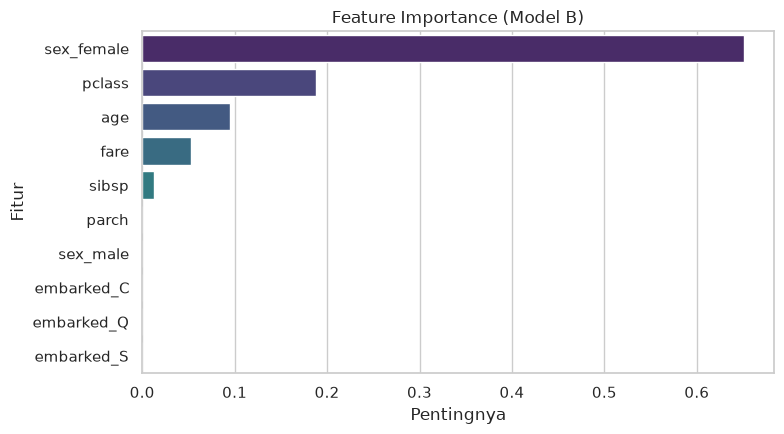

,Fitur,Pentingnya
5,sex_female,0.6509
0,pclass,0.1880
1,age,0.0952
4,fare,0.0526
2,sibsp,0.0133
3,parch,0.0000
6,sex_male,0.0000
7,embarked_C,0.0000
8,embarked_Q,0.0000
9,embarked_S,0.0000


In [12]:
fi = pd.DataFrame({'Fitur': X.columns, 'Pentingnya': model_b.feature_importances_}).sort_values('Pentingnya', ascending=False)
plt.figure(figsize=(8,4.5))
sns.barplot(x='Pentingnya', y='Fitur', data=fi, hue='Fitur', palette='viridis', legend=False)
plt.title('Feature Importance (Model B)'); plt.tight_layout()
plt.savefig('../reports/06_feature_importance.png', dpi=150); plt.show()
fi.round(4)

Jenis kelamin (`sex_female`) mendominasi, diikuti `pclass`, `age`, dan `fare`. Fitur `parch`, `embarked_*` tidak dipakai oleh pohon dengan kedalaman 3.

## 9. Simpan Model (Joblib)

In [13]:
joblib.dump(model_b, '../model/model_b.joblib')
meta = dict(features=list(X.columns), median_age=median_age, mode_embarked=mode_embarked,
            metrics=dict(train_acc=float(hasil['Model B (max_depth=3)']['train']),
                         test_acc=float(hasil['Model B (max_depth=3)']['test'])),
            max_depth=3)
json.dump(meta, open('../model/meta.json', 'w'), indent=2)
# uji muat ulang
m = joblib.load('../model/model_b.joblib')
print('Akurasi test setelah load:', round(m.score(X_test, y_test), 4))

Akurasi test setelah load: 0.7948
